# 1 · Static methods (the baseline)

Before training anything, measure the interpolators that need **no model**.

The task is **2x frame generation by interpolation**: the stream sends every second frame,
and once received frame N+2 is in, the client makes frame N+1 - the one the host never sent -
from N and N+2, and shows it before N+2. Every method below gets those two frames and is
scored on N+1. Both ends of the motion are known, which is the whole difference from
`../frame_gen_extra/`: there a scroll that stops between N and N+1 cannot be told from one
that goes on; here N+2 shows which.

The bar is set on two sides:

- **hold** - N shown twice, what a 30 fps stream drawn at 60 is with interpolation off;
- **the mock** - the mean of N and N+2, the graph desktop-streamer's client runs today as
  `interpolate.onnx`.

At the end the best method that builds from fixed operators is exported with the client's
contract, beside the mock's mean as a baseline graph.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "Static methods".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, show, training, webexport
from helpers.training import DATA_DIR, DEVICE

SEED = 0

manifest = training.load_manifest()
training.describe(manifest)
HALO = manifest["halo"]

# every validation run at its fixed sample: (N, N+2), and N+1 between them
inputs, targets = runs.load(DATA_DIR, "val", manifest)
masks = runs.groups(manifest, "val", inputs, targets, HALO)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for kind in KINDS:
    masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
print("val    ", inputs.shape, "->", targets.shape)
print("samples", {name: int(mask.sum()) for name, mask in masks.items() if "," not in name})

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N and N+2, the target N+1 between them (2x frame generation)


val     (1730, 2, 96, 96, 3) -> (1730, 96, 96, 3)
samples {'all': 1730, 'changed': 868, 'unchanged': 862, 'cursor': 178, 'page': 731, 'desktop': 439, 'video': 160, 'photo': 400}


## The methods

| method | how it makes N+1 from N and N+2 | in a graph? |
| --- | --- | --- |
| hold N | N again | `Identity` |
| hold N+2 | N+2 early | `Identity` |
| mean (the mock) | ½ N + ½ N+2 per pixel | `Add`, `Mul` |
| shift, tile | the whole-pixel motion d that best carries N onto N+2, searched over every d within the halo; N moved d/2 forwards and N+2 moved d/2 back, averaged | no: torch reference |
| shift, tile, from N only | the same, N moved only | no |
| shift, 16 px blocks | the same search per 16 px block of N+2 | no |
| bilateral, 16 / 8 px blocks | per block of N+1, the d (±8 px) whose two ends - N at -d/2, N+2 at +d/2 - agree best; their mean | no |
| **tile search** | extrapolation's published search: the costs of the 81 motions within ±8 px on half-resolution luma, every second position, averaged over the tile, a softmax; half of it each way | **yes**: `Conv`, `Softmax`, `MatMul`, `GridSample` |
| **tile search + pick** | the tile search, and per pixel a soft choice between it and the mean, by which of the two agrees with itself better there | **yes**: a few more elementwise operators and an `AveragePool` |

The pick is what interpolation can do and extrapolation cannot. Moving N and N+2 towards each
other by a motion gives two reads of every pixel of N+1; where the motion is right they show
the same content, where it is wrong they do not - a dragged window's still desktop around it,
a menu that opens. That disagreement is measured *at the pixel being drawn*, so it is
evidence for the choice. Extrapolation's notebook 4 found its picker had none.

Nothing here learns. Set by hand: the radius of the searches, the block sizes, and the pick's
window and sharpness - those two chosen on train runs, below.

In [2]:
"""The pick's two numbers, chosen on 2,000 train runs (their fixed sample) - not on validation."""

train_inputs, train_targets = runs.load(DATA_DIR, "train", manifest, count=2000)
train_masks = {"changed": runs.changed(train_inputs[:, 0], train_inputs[:, 1], train_targets, HALO)}

def search():
    return models.TileSearch(radius=4, scale=2, sharpness=10.0, stride=2, fraction=0.5, still=0.1)

pick_scores = {}
for window in (3, 5, 9, 15):
    for sharpness in (0.3, 1.0, 3.0):
        model = models.TilePick(search(), window=window, sharpness=sharpness)
        pick_scores[window, sharpness] = training.evaluate(model, train_inputs, train_targets, train_masks,
                                                           trim=HALO)["changed"]["wpsnr"]
base = training.evaluate(models.Interpolate(search()), train_inputs, train_targets, train_masks, trim=HALO)
print(f"train, {train_masks['changed'].sum()} changed samples: tile search alone {base['changed']['wpsnr']:.2f} dB")
print(f"{'window':>8}" + "".join(f"{f'sharp {s}':>11}" for s in (0.3, 1.0, 3.0)))
for window in (3, 5, 9, 15):
    print(f"{window:8}" + "".join(f"{pick_scores[window, s]:11.2f}" for s in (0.3, 1.0, 3.0)))
WINDOW, SHARPNESS = max(pick_scores, key=pick_scores.get)
print(f"chosen: window {WINDOW}, sharpness {SHARPNESS}")

train, 774 changed samples: tile search alone 35.90 dB
  window  sharp 0.3  sharp 1.0  sharp 3.0
       3      32.21      32.72      33.06
       5      33.40      34.35      34.62
       9      33.99      35.20      35.80
      15      33.99      35.18      35.96
chosen: window 15, sharpness 3.0


In [3]:
"""The methods, and their quality on every validation sample, by group."""

METHODS = {
    "hold N": models.Hold(),
    "hold N+2": models.Blend(1.0),
    "mean (the mock)": models.Blend(0.5),
    "shift, tile": models.Shift(radius=HALO, block=None),
    "shift, tile, from N only": models.Shift(radius=HALO, block=None, side="previous"),
    "shift, 16 px blocks": models.Shift(radius=HALO, block=16),
    "bilateral, 16 px blocks": models.Bilateral(radius=8, block=16),
    "bilateral, 8 px blocks": models.Bilateral(radius=8, block=8),
    "tile search": models.Interpolate(search()),
    "tile search + pick": models.TilePick(search(), window=WINDOW, sharpness=SHARPNESS),
}

results = {name: training.evaluate(method.to(DEVICE), inputs, targets, masks, trim=HALO, batch_size=128)
           for name, method in METHODS.items()}

for group in ("changed", "all", "unchanged"):
    print(f"\n{group}: {masks[group].sum()} samples")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['hold N'][g]['wpsnr']:+6.2f} dB vs hold"
                                                       f"   {s['wpsnr'] - results['mean (the mock)'][g]['wpsnr']:+6.2f} vs mean")


changed: 868 samples
                              wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
hold N                        26.89    25.72    59.44    60.84     25.46   0.6663    +0.00 dB vs hold    -1.29 vs mean
hold N+2                      27.34    26.20    59.97    61.42     25.87   0.6679    +0.45 dB vs hold    -0.84 vs mean
mean (the mock)               28.18    26.99    61.42    62.90     26.79   0.6938    +1.29 dB vs hold    +0.00 vs mean
shift, tile                   38.03    37.21    66.02    67.25     36.16   0.9226   +11.14 dB vs hold    +9.84 vs mean
shift, tile, from N only      38.60    37.83    65.39    66.51     36.67   0.9177   +11.72 dB vs hold   +10.42 vs mean
shift, 16 px blocks           37.56    36.74    65.91    67.16     35.70   0.9221   +10.67 dB vs hold    +9.38 vs mean
bilateral, 16 px blocks       37.30    36.52    65.49    66.73     35.41   0.9082   +10.42 dB vs hold    +9.12 vs mean
bilateral, 8 px blocks        36.52    35.72    64.47    65.90 

In [4]:
"""By kind of source, on the samples where something changed."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<26}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        print(f"{name:<26}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print(f"{'samples':<26}" + "".join(f"{masks[f'{kind}, changed'].sum():10}" for kind in KINDS) + "\n")

SSIM-Y, changed                 page   desktop     photo     video    cursor
hold N                        0.6424    0.7288    0.5535    0.9462    0.6473
hold N+2                      0.6431    0.7317    0.5541    0.9516    0.6356
mean (the mock)               0.6578    0.7290    0.6129    0.9663    0.6662
shift, tile                   0.9145    0.7896    0.9638    0.9848    0.8704
shift, tile, from N only      0.9094    0.7962    0.9553    0.9777    0.8703
shift, 16 px blocks           0.9074    0.8141    0.9630    0.9826    0.8852
bilateral, 16 px blocks       0.8842    0.8055    0.9543    0.9812    0.8596
bilateral, 8 px blocks        0.8614    0.8056    0.9458    0.9768    0.8567
tile search                   0.8897    0.7786    0.9625    0.9811    0.8505
tile search + pick            0.8909    0.7924    0.9620    0.9822    0.8664
samples                          375       113       266       114        60

wPSNR (dB), changed             page   desktop     photo     video    curso

In [5]:
"""Per sample: how often each method beats hold and the mean, on the changed samples, in luma PSNR."""

changed = np.flatnonzero(masks["changed"])
truth = runs.trim(training.to_tensor(targets[changed]), HALO).cpu()
per_sample = {}
for name in ("hold N", "mean (the mock)", "shift, tile", "tile search", "tile search + pick"):
    made = runs.trim(training.predict(METHODS[name], inputs[changed], 128), HALO)
    per_sample[name] = metrics.per_image(made, truth)["y"].clamp(max=99).numpy()   # luma PSNR per sample
for name in ("shift, tile", "tile search", "tile search + pick"):
    gain = per_sample[name] - per_sample["hold N"]
    over_mean = per_sample[name] - per_sample["mean (the mock)"]
    print(f"{name:<22} vs hold: better on {np.mean(gain > 0):5.1%}, worst {gain.min():+6.2f} dB (luma), median {np.median(gain):+5.2f}"
          f"   vs mean: better on {np.mean(over_mean > 0):5.1%}, worst {over_mean.min():+6.2f} dB")

shift, tile            vs hold: better on 91.4%, worst -71.56 dB (luma), median +11.30   vs mean: better on 76.7%, worst  -8.14 dB
tile search            vs hold: better on 92.1%, worst -70.50 dB (luma), median +11.17   vs mean: better on 76.5%, worst  -7.17 dB
tile search + pick     vs hold: better on 92.6%, worst -70.50 dB (luma), median +11.18   vs mean: better on 76.7%, worst  -3.12 dB


## The halo

The client's tile has a halo of 4 pixels; the set stores 16. Content moves two display frames
between N and N+2, and N+1 needs content from at most half that far - but the *search* needs
to see the whole motion to find it. The tile search reads past a small halo (the edge
repeated); the exact shift can only search as far as the halo.

In [6]:
"""The graphs and the exact shift at the client's halo and wider."""

HALOS = [4, 8, 16]
by_halo = {}
for halo in HALOS:
    x, y = runs.load(DATA_DIR, "val", manifest, halo=halo)
    for name, model in (("shift, tile", models.Shift(radius=halo, block=None)),
                        ("tile search", models.Interpolate(search())),
                        ("tile search + pick", models.TilePick(search(), window=WINDOW, sharpness=SHARPNESS)),
                        ("mean (the mock)", models.Blend(0.5))):
        by_halo[halo, name] = training.evaluate(model, x, y, {"changed": masks["changed"]}, trim=halo)["changed"]

print(f"{'changed samples':<22}" + "".join(f"{f'halo {h}':>18}" for h in HALOS))
print(f"{'':<22}" + "".join(f"{'SSIM-Y':>9}{'wPSNR':>9}" for _ in HALOS))
for name in ("shift, tile", "tile search", "tile search + pick", "mean (the mock)"):
    print(f"{name:<22}" + "".join(f"{by_halo[h, name]['ssim']:9.4f}{by_halo[h, name]['wpsnr']:9.2f}" for h in HALOS))

changed samples                   halo 4            halo 8           halo 16
                         SSIM-Y    wPSNR   SSIM-Y    wPSNR   SSIM-Y    wPSNR
shift, tile              0.8293    32.66   0.9085    37.39   0.9226    38.03
tile search              0.9087    36.86   0.9102    37.20   0.9096    37.52
tile search + pick       0.9117    36.83   0.9124    37.30   0.9119    37.57
mean (the mock)          0.6938    28.18   0.6938    28.18   0.6938    28.18


## What they look like

One changed sample of each kind whose content really moves: N, N+2, the truth, and what the
methods make of it. The red box is what is scored. The mean draws every moved edge twice at
half strength; the motion methods draw it once, where the tile's one motion is right.

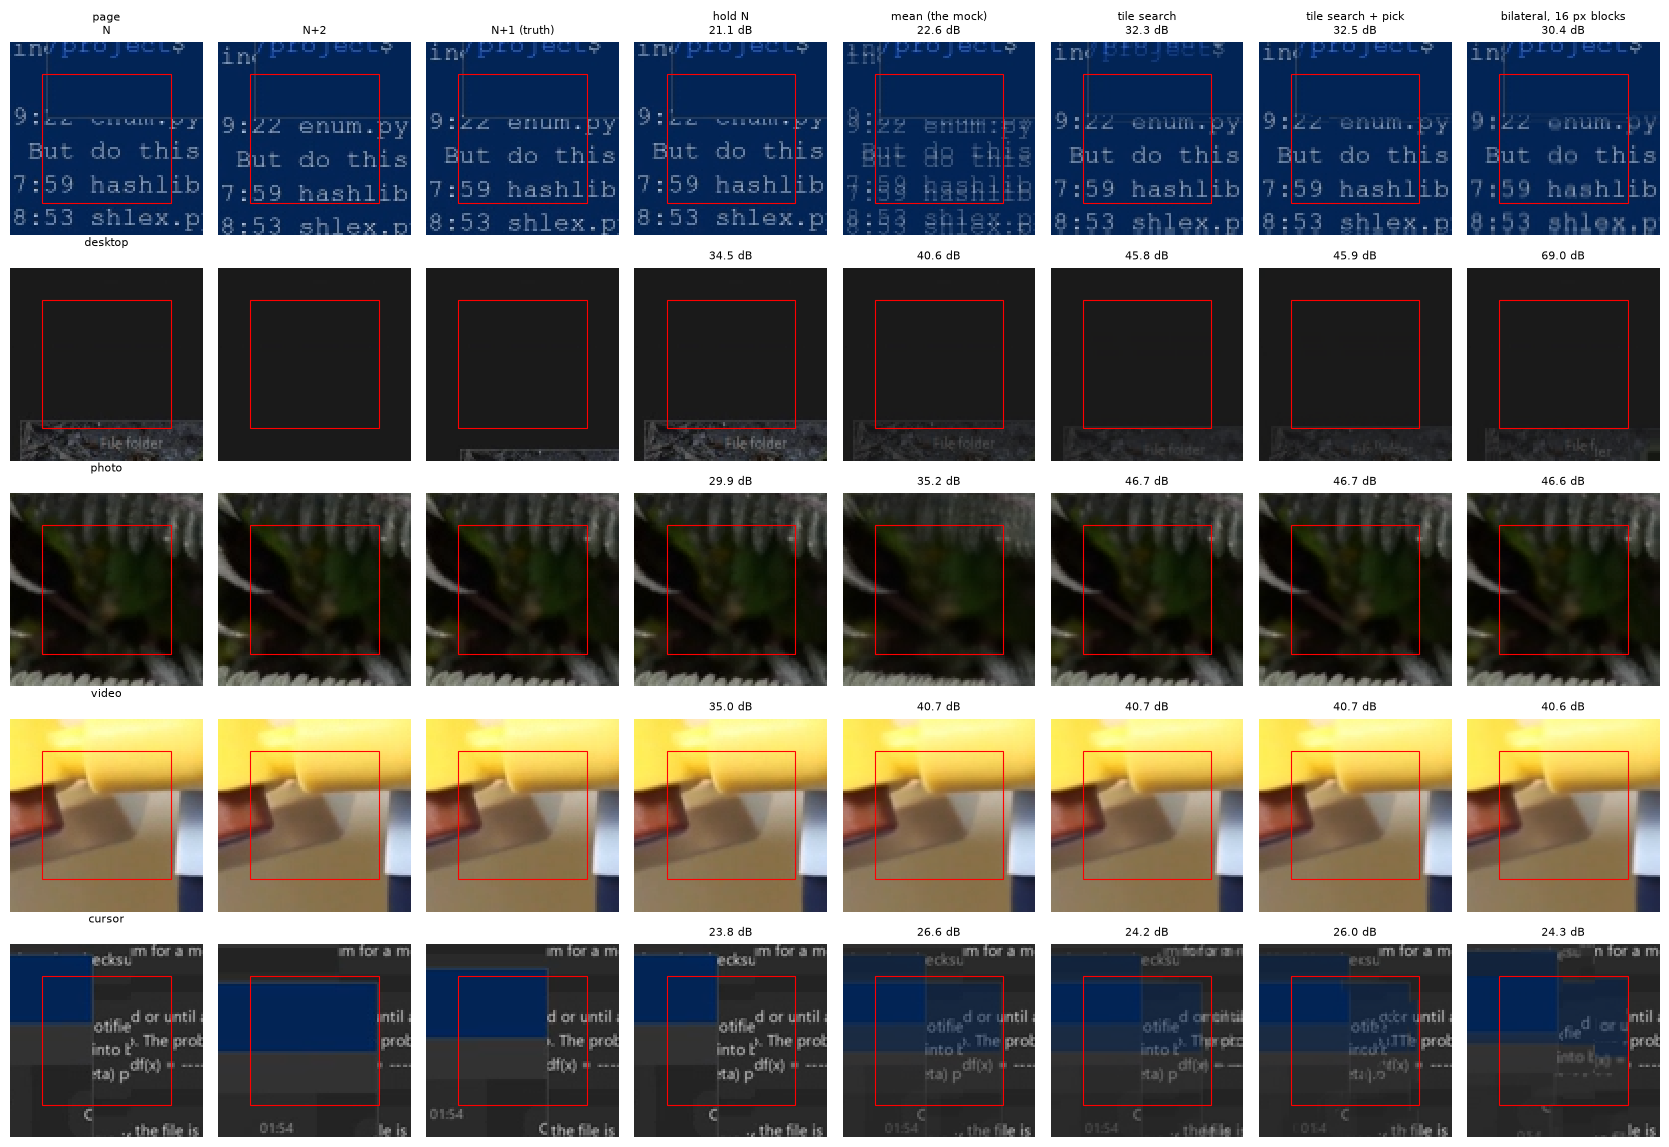

In [7]:
"""One moving sample of each kind through the methods."""

show_names = ["hold N", "mean (the mock)", "tile search", "tile search + pick", "bilateral, 16 px blocks"]
picks = show.moving_picks(inputs, targets, masks, KINDS, HALO, seed=SEED)
box = (HALO, HALO, manifest["core"], manifest["core"])
columns = ["N", "N+2", "N+1 (truth)", *show_names]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    previous, current = training.to_tensor(inputs[index:index + 1]).unbind(1)
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"N": previous, "N+2": current, "N+1 (truth)": truth}
    with torch.no_grad():
        for name in show_names:
            pictures[name] = METHODS[name].to(DEVICE)(previous, current).clamp(0, 1)
    for column, name in enumerate(columns):
        title = name if row == 0 else ""
        if name in show_names:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        show.picture(axes[row][column], pictures[name], title, box)
fig.tight_layout()
plt.show()

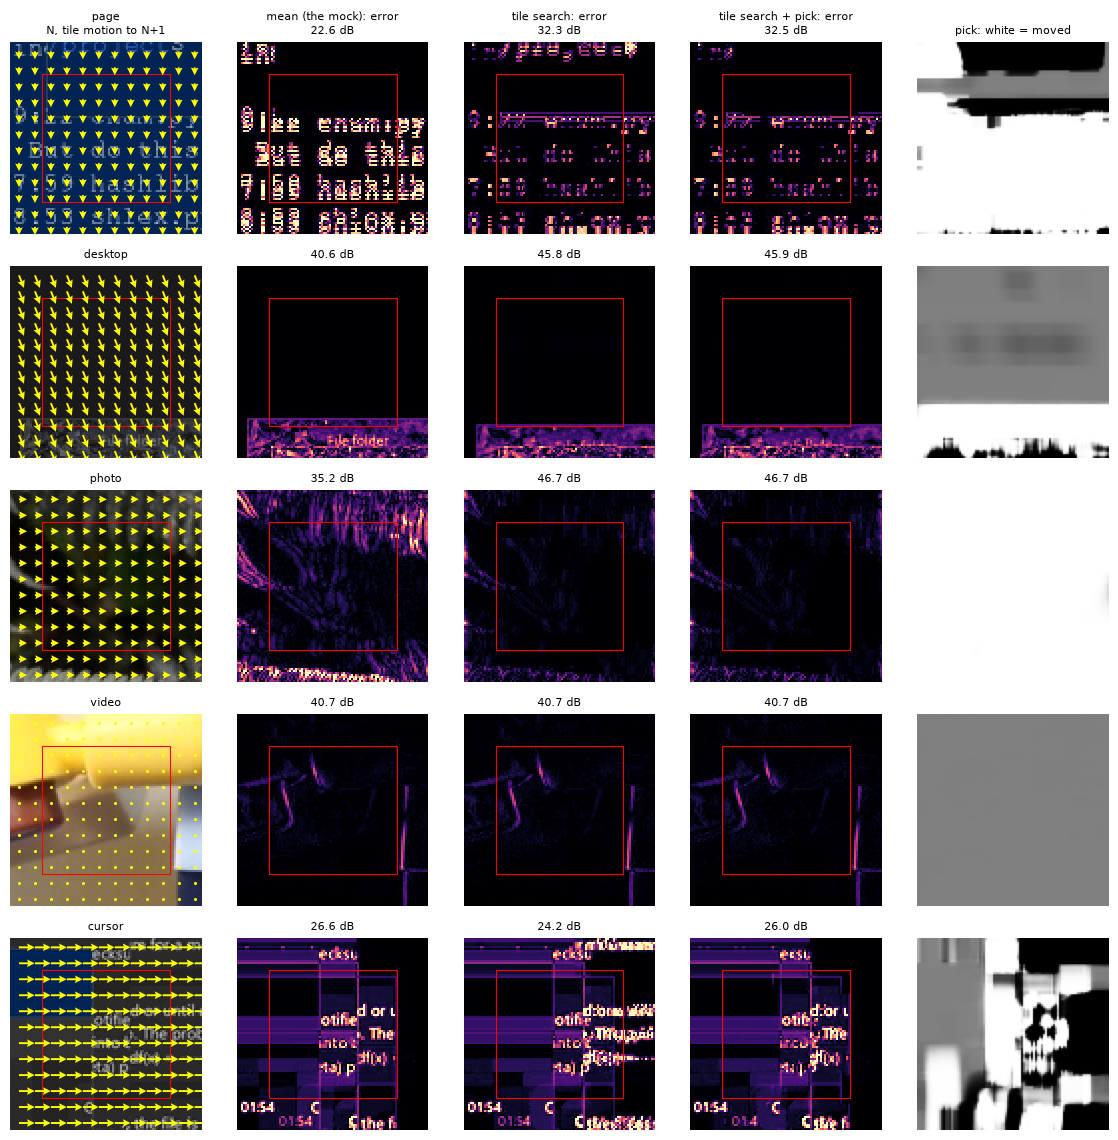

errors full colour at 48 luma levels; arrows where content goes from N to N+1, twice their length


In [8]:
"""Where each is wrong: errors on one colour scale, and where the pick took the motion."""

fig, axes = plt.subplots(len(picks), 5, figsize=(2.3 * 5, 2.3 * len(picks)), squeeze=False)
pick = METHODS["tile search + pick"]
for row, (kind, index) in enumerate(picks):
    previous, current = training.to_tensor(inputs[index:index + 1]).unbind(1)
    truth = training.to_tensor(targets[index:index + 1])
    with torch.no_grad():
        offsets = pick.search(previous, current).expand(-1, -1, *current.shape[-2:])
        before, after = models.warp(previous, -offsets), models.warp(current, offsets)
        weight = torch.sigmoid(pick.sharpness * (pick.disagreement(previous, current) - pick.disagreement(before, after)))
        made = {name: METHODS[name](previous, current) for name in ("mean (the mock)", "tile search", "tile search + pick")}
    show.motion(axes[row][0], previous, -offsets, f"{kind}\nN, tile motion to N+1" if row == 0 else kind, box)
    for column, (name, picture) in enumerate(made.items(), 1):
        score = metrics.wpsnr(runs.trim(picture, HALO), runs.trim(truth, HALO))
        show.error(axes[row][column], picture, truth, f"{name}: error\n{score:.1f} dB" if row == 0 else f"{score:.1f} dB", box)
    axes[row][4].imshow(weight[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[row][4].set_title("pick: white = moved" if row == 0 else "", fontsize=8)
    axes[row][4].axis("off")
fig.tight_layout()
plt.show()
print(f"errors full colour at {show.LEVELS} luma levels; arrows where content goes from N to N+1, twice their length")

## Export to ONNX for the client

The client runs `interpolate.onnx` on 328x188 tiles (a 320x180 step and a halo of 4), all of a
frame's tiles in one batch, with two inputs, `previous` (N) and `current` (N+2). Published
into `dist/frame_gen_intra/`:

- `interpolate_static_mean_tile320x180.onnx` - the mock's mean, as a baseline graph;
- the tile search and the tile search + pick, each with `N`, `H` and `W` symbolic as the
  client needs (`interpolate2x_*.onnx`, one file for every tile count and size), and pinned to
  36 tiles of 328x188 - one 1080p frame - for the benchmark page (`_tile320x180_b36`).

Each graph is checked against torch at 36 tiles, 4 tiles, and one tile of 64x32 (a frame
smaller than a tile), and timed on the desktop CPU. Its browser time is the benchmark page's
to measure (`../upscale/benchmark/main.py --models ../../dist/frame_gen_intra`).

In [9]:
"""Export the mean and the two graphs, check them against torch, time them on the CPU."""

step_h, step_w = webexport.TILE_STEP
rng = np.random.default_rng(SEED)

info = webexport.export(models.Blend(0.5), f"interpolate_static_mean_tile{step_w}x{step_h}.onnx",
                        webexport.TILE_INPUT, label="static mean (the mock)")
webexport.check_graph(info["path"], models.Blend(0.5), *rng.random((2, 1, 3, *webexport.TILE_INPUT), dtype=np.float32))
ms = webexport.time_graph(info["path"], webexport.TILE_INPUT)
webexport.annotate(info, cpu_ms=round(ms, 3))
print(webexport.summary_line(info, ms))

PUBLISHED = {
    "tilesearch_r4_s2": ("tile search, radius 4 at half resolution, stride 2", models.Interpolate(search())),
    "tilepick_r4_s2": (f"tile search + pick, window {WINDOW}, sharpness {SHARPNESS}",
                       models.TilePick(search(), window=WINDOW, sharpness=SHARPNESS)),
}
# real frames for the check, so the search has a motion to find: 36 validation tiles cut to
# the client's tile from a moving sample, and random pictures for the shapes
moving = np.flatnonzero(masks["changed"])[:36]
# the pick's sigmoid of a disagreement in luma levels turns a float rounding of the runtime's
# into a little more than the export's default allows, on a few pixels of millions
TOLERANCE = 5e-3
for name, (label, model) in PUBLISHED.items():
    model = model.cpu().eval()
    dynamic = webexport.export(model, f"interpolate2x_{name}.onnx", webexport.TILE_INPUT, label=label, dynamic=True)
    fixed = webexport.export(model, f"interpolate2x_{name}_tile{step_w}x{step_h}_b36.onnx", webexport.TILE_INPUT,
                             label=f"{label}, 36 tiles", batch=36)
    for batch, size in ((36, webexport.TILE_INPUT), (4, webexport.TILE_INPUT), (1, (32, 64))):
        frames = rng.random((2, batch, 3, *size), dtype=np.float32)
        webexport.check_graph(dynamic["path"], model, *frames, tolerance=TOLERANCE)
    sample = np.moveaxis(inputs[moving], -1, -3).astype(np.float32) / 255     # (36, 2, 3, 96, 96)
    worst = webexport.check_graph(dynamic["path"], model, np.ascontiguousarray(sample[:, 0]),
                                  np.ascontiguousarray(sample[:, 1]), tolerance=TOLERANCE)
    webexport.check_graph(fixed["path"], model, *rng.random((2, 36, 3, *webexport.TILE_INPUT), dtype=np.float32),
                          tolerance=TOLERANCE)
    for info, batch in ((dynamic, 1), (fixed, 36)):
        ms = webexport.time_graph(info["path"], webexport.TILE_INPUT, batch=batch)
        webexport.annotate(info, cpu_ms=round(ms, 3))
        print(webexport.summary_line(info, ms))
    print(f"   matches torch to {worst:.1e} on real moving samples")

print(f"\nwritten to {webexport.MODELS_DIR}")

interpolate_static_mean_tile320x180.onnx                0.5 KB    0.02 ms   Addx1, Constantx2, Mulx2   OUTSIDE BUDGET: Mul


interpolate2x_tilesearch_r4_s2.onnx                    40.1 KB    2.97 ms   Absx1, Addx9, Castx9, Concatx7, Constantx58, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx8, GreaterOrEqualx1, GridSamplex2, MatMulx1, Mulx13, Negx1, Rangex4, Reciprocalx4, ReduceMeanx1, Reshapex5, Shapex5, Slicex1, Softmaxx1, Subx5, Unsqueezex12, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Neg, Range, Reciprocal, ReduceMean, Reshape, Shape, Slice, Softmax, Sub, Unsqueeze, Where


interpolate2x_tilesearch_r4_s2_tile320x180_b36.onnx    39.7 KB  106.70 ms   Absx1, Addx9, Castx1, Concatx2, Constantx39, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx4, GreaterOrEqualx1, GridSamplex2, MatMulx1, Mulx13, Negx1, Reciprocalx4, ReduceMeanx1, Slicex1, Softmaxx1, Subx5, Unsqueezex6, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Neg, Reciprocal, ReduceMean, Slice, Softmax, Sub, Unsqueeze, Where
   matches torch to 6.7e-06 on real moving samples


/home/henrik/projects/desktop-streamer-ai/.venv/lib/python3.14/site-packages/torch/onnx/_internal/torchscript_exporter/jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version)
/home/henrik/projects/desktop-streamer-ai/.venv/lib/python3.14/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:709: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_graph_shape_type_inference(
/home/henrik/projects/desktop-streamer-ai/.venv/lib/python3.14/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1182: UserWarning: C

interpolate2x_tilepick_r4_s2.onnx                      45.6 KB    3.52 ms   Absx3, Addx11, AveragePoolx2, Castx11, Concatx9, Constantx83, ConstantOfShapex3, Convx4, Equalx1, Expandx1, Gatherx8, GreaterOrEqualx1, GridSamplex2, MatMulx1, Mulx22, Negx1, Padx2, Rangex4, Reciprocalx4, ReduceMeanx1, ReduceSumx4, Reshapex9, Shapex5, Sigmoidx1, Slicex3, Softmaxx1, Subx9, Transposex2, Unsqueezex12, Wherex1   OUTSIDE BUDGET: Abs, AveragePool, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Neg, Pad, Range, Reciprocal, ReduceMean, ReduceSum, Reshape, Shape, Sigmoid, Slice, Softmax, Sub, Transpose, Unsqueeze, Where


interpolate2x_tilepick_r4_s2_tile320x180_b36.onnx      45.2 KB  131.77 ms   Absx3, Addx11, AveragePoolx2, Castx3, Concatx4, Constantx64, ConstantOfShapex3, Convx4, Equalx1, Expandx1, Gatherx4, GreaterOrEqualx1, GridSamplex2, MatMulx1, Mulx22, Negx1, Padx2, Reciprocalx4, ReduceMeanx1, ReduceSumx4, Reshapex4, Sigmoidx1, Slicex3, Softmaxx1, Subx9, Transposex2, Unsqueezex6, Wherex1   OUTSIDE BUDGET: Abs, AveragePool, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Neg, Pad, Reciprocal, ReduceMean, ReduceSum, Reshape, Sigmoid, Slice, Softmax, Sub, Transpose, Unsqueeze, Where
   matches torch to 6.3e-05 on real moving samples

written to /home/henrik/projects/desktop-streamer-ai/dist/frame_gen_intra


## The bar to beat

In [10]:
changed = {name: scores["changed"] for name, scores in results.items()}
for name in ("hold N", "mean (the mock)", "shift, tile", "bilateral, 16 px blocks", "tile search", "tile search + pick"):
    s = changed[name]
    print(f"{name:<26}{s['wpsnr']:7.2f} dB {s['ssim']:.4f} SSIM-Y   {s['wpsnr'] - changed['hold N']['wpsnr']:+6.2f} dB vs hold")
print(f"on the {masks['changed'].sum()} changed validation samples")
print("next: whole frames in the client's tiles, and the browser's time")

hold N                      26.89 dB 0.6663 SSIM-Y    +0.00 dB vs hold
mean (the mock)             28.18 dB 0.6938 SSIM-Y    +1.29 dB vs hold
shift, tile                 38.03 dB 0.9226 SSIM-Y   +11.14 dB vs hold
bilateral, 16 px blocks     37.30 dB 0.9082 SSIM-Y   +10.42 dB vs hold
tile search                 37.52 dB 0.9096 SSIM-Y   +10.63 dB vs hold
tile search + pick          37.57 dB 0.9119 SSIM-Y   +10.68 dB vs hold
on the 868 changed validation samples
next: whole frames in the client's tiles, and the browser's time
